<a href="https://colab.research.google.com/github/sikdarananya/Assignments/blob/master/2026CT05047_CNN_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DEEP NEURAL NETWORKS - ASSIGNMENT 2: CNN FOR IMAGE CLASSIFICATION

## Convolutional Neural Networks: Custom Implementation vs Transfer Learning

STUDENT INFORMATION (REQUIRED - DO NOT DELETE)

BITS ID: 2026CT05047

Name: ANANYA SIKDAR

Email: 2026ct05047@wilp.bits-piliani.ac.in

Date: 21.11.2026

In [1]:
# Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
import time
import json
import os

SEED = 42
np.random.seed(SEED)

In [2]:
# Image processing utilities
# Deep learning frameworks (Keras / TensorFlow)
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

tf.random.set_seed(SEED)

# For image processing
from PIL import Image
import cv2

### 1.1 Dataset Selection and Loading

TODO: Load your chosen dataset

In [3]:
import zipfile
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

IMG_SIZE = 224
SAMPLES_PER_CLASS = 1000
class_names = ['cat', 'dog']

url = "https://download.microsoft.com/download/3/e/1/3e1c3f21-ecdb-4869-8368-6deba77b919f/kagglecatsanddogs_5340.zip"
zip_path = keras.utils.get_file("kagglecatsanddogs_5340.zip", origin=url, extract=False)

extract_dir = os.path.join(os.path.dirname(zip_path), "cats_vs_dogs_extracted")
if not os.path.exists(extract_dir):
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)

folder_map = {0: "Cat", 1: "Dog"}
images_by_class = {0: [], 1: []}

for label_idx, folder_name in folder_map.items():
    class_dir = None
    for root, dirs, _ in os.walk(extract_dir):
        if folder_name in dirs:
            class_dir = os.path.join(root, folder_name)
            break
    if class_dir is None:
        raise FileNotFoundError(f"Could not find '{folder_name}' folder inside {extract_dir}")

    for fname in sorted(os.listdir(class_dir)):
        if len(images_by_class[label_idx]) >= SAMPLES_PER_CLASS:
            break
        if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        fpath = os.path.join(class_dir, fname)
        try:
            with Image.open(fpath) as im:
                im = im.convert("RGB")
                arr = np.asarray(im, dtype=np.uint8)
            if arr.ndim != 3 or arr.shape[2] != 3 or arr.size == 0:
                continue
            resized = cv2.resize(arr, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
            images_by_class[label_idx].append(resized)
        except Exception:
            continue

# Check AFTER both classes are loaded (min 500 images per class required)
if len(images_by_class[0]) < 500 or len(images_by_class[1]) < 500:
    raise ValueError(
        f"Fewer than 500 valid images found: cat={len(images_by_class[0])}, dog={len(images_by_class[1])}"
    )

X_raw = np.array(images_by_class[0] + images_by_class[1], dtype=np.uint8)
y_raw = np.array([0] * len(images_by_class[0]) + [1] * len(images_by_class[1]), dtype=np.int32)

counts = [int(np.sum(y_raw == i)) for i in range(len(class_names))]

# REQUIRED: Fill in these metadata fields
dataset_name = "Cats vs Dogs (Balanced Subset)"
dataset_source = "Microsoft Cats vs Dogs Dataset (PetImages)"
n_samples = int(len(X_raw))
n_classes = int(len(class_names))
samples_per_class = f"min: {min(counts)}, max: {max(counts)}, avg: {np.mean(counts):.1f}"
image_shape = [IMG_SIZE, IMG_SIZE, 3]  # [height, width, channels]
problem_type = "classification"

824887076/824887076 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


In [4]:
# Primary metric selection
primary_metric = "accuracy"
metric_justification = """
The Cats vs Dogs subset is balanced across both classes with equal false-positive and false-negative costs, making accuracy an appropriate primary metric alongside macro-averaged precision, recall, and F1-score.
""".strip()

In [5]:
print("DATASET INFORMATION")
print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Total Samples: {n_samples}")
print(f"Number of Classes: {n_classes}")
print(f"Samples per Class: {samples_per_class}")
print(f"Image Shape: {image_shape}")
print(f"Primary Metric: {primary_metric}")
print(f"Metric Justification: {metric_justification}")

DATASET INFORMATION
Dataset: Cats vs Dogs (Balanced Subset)
Source: Microsoft Cats vs Dogs Dataset (PetImages)
Total Samples: 2000
Number of Classes: 2
Samples per Class: min: 1000, max: 1000, avg: 1000.0
Image Shape: [224, 224, 3]
Primary Metric: accuracy
Metric Justification: The Cats vs Dogs subset is balanced across both classes with equal false-positive and false-negative costs, making accuracy an appropriate primary metric alongside macro-averaged precision, recall, and F1-score.


### 1.2 Data Exploration and Visualization

- TODO: Show sample images from each class
- TODO: Plot class distribution
- TODO: Display image statistics

### 1.3 Data Preprocessing
- TODO: Resize images to consistent size
- TODO: Normalize pixel values
- TODO: Split into train/test (90/10 or 85/15)

Pixel min: 0, max: 255, mean: 116.75, std: 66.06
Class 'cat' (id=0): count=1000, mean_pixel=116.32
Class 'dog' (id=1): count=1000, mean_pixel=117.17


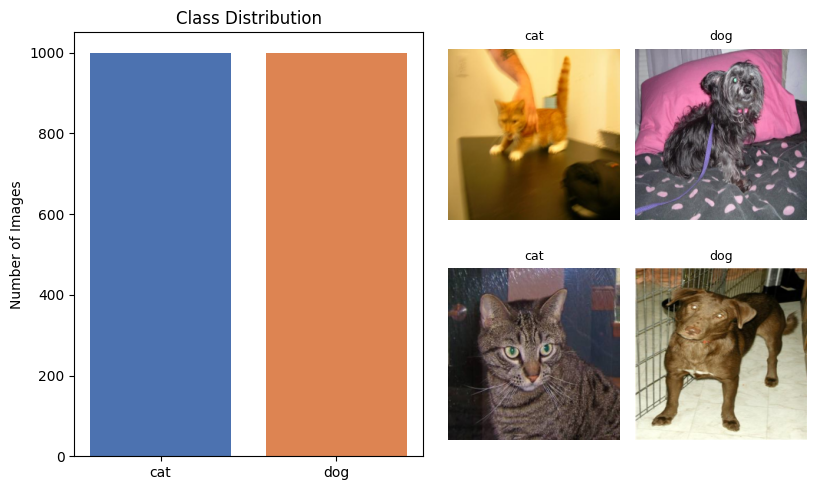

In [6]:
# Image pixel statistics
print(f"Pixel min: {X_raw.min()}, max: {X_raw.max()}, mean: {X_raw.mean():.2f}, std: {X_raw.std():.2f}")
for idx, cname in enumerate(class_names):
    c_imgs = X_raw[y_raw == idx]
    print(f"Class '{cname}' (id={idx}): count={len(c_imgs)}, mean_pixel={c_imgs.mean():.2f}")

# Plot class distribution and sample images
fig = plt.figure(figsize=(12, 5))
ax_bar = fig.add_subplot(1, 3, 1)
ax_bar.bar(class_names, counts, color=['#4C72B0', '#DD8452'])
ax_bar.set_title('Class Distribution')
ax_bar.set_ylabel('Number of Images')

for i in range(4):
    row = i // 2
    col = i % 2
    ax_img = fig.add_subplot(2, 6, row * 6 + 3 + col)
    sample_idx = np.where(y_raw == (i % 2))[0][i // 2]
    ax_img.imshow(X_raw[sample_idx])
    ax_img.set_title(class_names[y_raw[sample_idx]], fontsize=9)
    ax_img.axis('off')

plt.tight_layout()
plt.show()

In [7]:
X_train_raw, X_test_raw, y_train_int, y_test_int = train_test_split(
    X_raw, y_raw, test_size=0.10, random_state=SEED, stratify=y_raw
)

# Normalized [0, 1] inputs and one-hot labels for categorical_crossentropy
X_train_cnn = X_train_raw.astype('float32') / 255.0
X_test_cnn = X_test_raw.astype('float32') / 255.0

# ResNet50 preprocessing
X_train_tl = resnet_preprocess(X_train_raw.astype('float32'))
X_test_tl = resnet_preprocess(X_test_raw.astype('float32'))

y_train = keras.utils.to_categorical(y_train_int, num_classes=n_classes)
y_test = keras.utils.to_categorical(y_test_int, num_classes=n_classes)

# REQUIRED: Document your split
train_test_ratio = "90/10"
train_samples = int(len(X_train_raw))
test_samples = int(len(X_test_raw))

In [8]:
print(f"\nTrain/Test Split: {train_test_ratio}")
print(f"Training Samples: {train_samples}")
print(f"Test Samples: {test_samples}")


Train/Test Split: 90/10
Training Samples: 1800
Test Samples: 200


### 2.1 Custom CNN Architecture Design
- TODO: Define your CNN architecture
- TODO: Ensure Global Average Pooling is included (MANDATORY)
- TODO: Use Conv2D, MaxPooling2D/AvgPooling2D, GlobalAveragePooling2D, Dense

In [9]:
cnn_learning_rate = 0.001
cnn_epochs = 15
cnn_batch_size = 32
cnn_optimizer_name = "Adam"
cnn_loss_name = "categorical_crossentropy"

def build_custom_cnn(input_shape, n_classes):
    """
    Build custom CNN architecture with Global Average Pooling (no Flatten).
    """
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation='softmax')
    ], name="custom_cnn_gap")
    return model

In [10]:
# Create model instance
custom_cnn = build_custom_cnn(tuple(image_shape), n_classes)
custom_cnn.summary()

Model: "custom_cnn_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,850 (1.49 MB)

 Trainable params: 389,890 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [11]:
# Compile model
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=cnn_learning_rate),
    loss=cnn_loss_name,
    metrics=['accuracy']
)

cnn_conv_layers = sum(1 for l in custom_cnn.layers if isinstance(l, layers.Conv2D))
cnn_pooling_layers = sum(1 for l in custom_cnn.layers if isinstance(l, (layers.MaxPooling2D, layers.AveragePooling2D, layers.GlobalAveragePooling2D)))
custom_cnn_total_params = int(custom_cnn.count_params())

### 2.2 Train Custom CNN

In [12]:
print("\nCUSTOM CNN TRAINING")
# Track training time
custom_cnn_start_time = time.time()


CUSTOM CNN TRAINING


In [13]:
cnn_history = custom_cnn.fit(
    X_train_cnn,
    y_train,
    epochs=cnn_epochs,
    batch_size=cnn_batch_size,
    validation_split=0.1,
    verbose=1
)

Epoch 1/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 48s 582ms/step - accuracy: 0.5802 - loss: 0.7536 - val_accuracy: 0.4167 - val_loss: 0.9290
Epoch 2/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.6068 - loss: 0.6722 - val_accuracy: 0.4167 - val_loss: 1.0512
Epoch 3/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.6253 - loss: 0.6502 - val_accuracy: 0.4167 - val_loss: 1.0452
Epoch 4/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.6463 - loss: 0.6354 - val_accuracy: 0.4167 - val_loss: 1.4886
Epoch 5/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.6543 - loss: 0.6276 - val_accuracy: 0.4167 - val_loss: 1.4113
Epoch 6/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.6654 - loss: 0.6048 - val_accuracy: 0.4167 - val_loss: 1.4172
Epoch 7/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.6840 - loss: 0.6004 - val_accuracy: 0.4389 - val_loss: 1.2748
Epoch 8/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.6870 - loss: 0.5795 - val_accuracy: 0.4278 

In [14]:
custom_cnn_training_time = time.time() - custom_cnn_start_time

In [15]:
# REQUIRED: Track initial and final loss
custom_cnn_initial_loss = float(cnn_history.history['loss'][0])
custom_cnn_final_loss = float(cnn_history.history['loss'][-1])

In [16]:
print(f"Training completed in {custom_cnn_training_time:.2f} seconds")
print(f"Initial Loss: {custom_cnn_initial_loss:.4f}")
print(f"Final Loss: {custom_cnn_final_loss:.4f}")

Training completed in 162.01 seconds
Initial Loss: 0.7536
Final Loss: 0.5235


In [17]:
print("\nCUSTOM CNN EVALUATION")


CUSTOM CNN EVALUATION


### 2.3 Evaluate Custom CNN
- TODO: Make predictions on test set
- TODO: Calculate all 4 required metrics

In [18]:
cnn_probs = custom_cnn.predict(X_test_cnn, verbose=0)
cnn_y_pred = np.argmax(cnn_probs, axis=1)

# REQUIRED: Calculate all 4 metrics
custom_cnn_accuracy = float(accuracy_score(y_test_int, cnn_y_pred))
custom_cnn_precision = float(precision_score(y_test_int, cnn_y_pred, average='macro', zero_division=0))
custom_cnn_recall = float(recall_score(y_test_int, cnn_y_pred, average='macro', zero_division=0))
custom_cnn_f1 = float(f1_score(y_test_int, cnn_y_pred, average='macro', zero_division=0))

In [19]:
print("\nCustom CNN Performance:")
print(f"Accuracy:  {custom_cnn_accuracy:.4f}")
print(f"Precision: {custom_cnn_precision:.4f}")
print(f"Recall:    {custom_cnn_recall:.4f}")
print(f"F1-Score:  {custom_cnn_f1:.4f}")


Custom CNN Performance:
Accuracy:  0.6750
Precision: 0.7104
Recall:    0.6750
F1-Score:  0.6607


### 2.4 Visualize Custom CNN Results
- TODO: Plot training loss curve
- TODO: Plot confusion matrix
- TODO: Show sample predictions

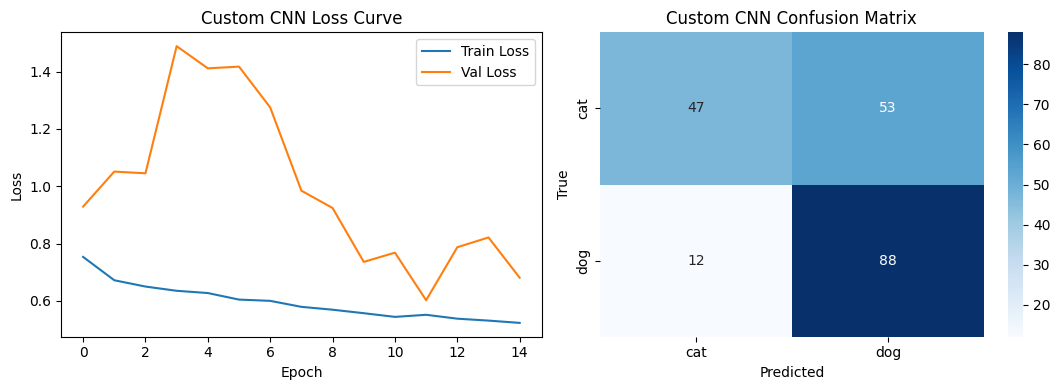

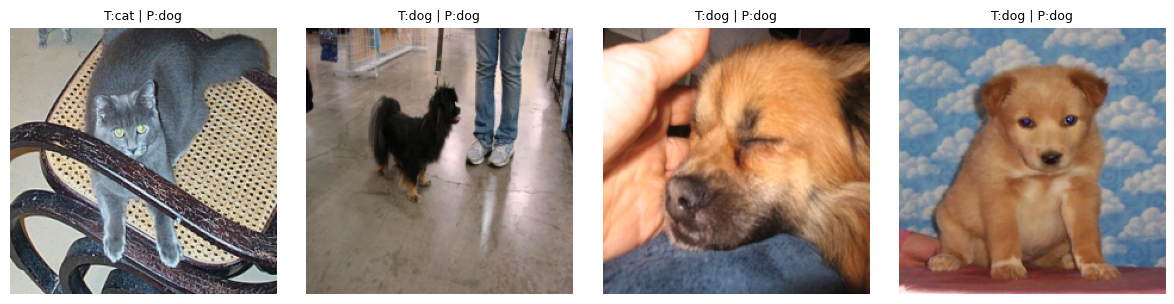

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cnn_history.history['loss'], label='Train Loss')
if 'val_loss' in cnn_history.history:
    axes[0].plot(cnn_history.history['val_loss'], label='Val Loss')
axes[0].set_title('Custom CNN Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

cm_cnn = confusion_matrix(y_test_int, cnn_y_pred)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Custom CNN Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    axes[i].imshow(X_test_raw[i])
    axes[i].set_title(f"T:{class_names[y_test_int[i]]} | P:{class_names[cnn_y_pred[i]]}", fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

### 3.1 Load Pre-trained Model and Modify Architecture

In [21]:
print("\n" + "="*70)
print("TRANSFER LEARNING IMPLEMENTATION")


TRANSFER LEARNING IMPLEMENTATION


In [22]:
# Choose and load pre-trained model
pretrained_model_name = "ResNet50"

In [23]:
tl_learning_rate = 0.001
tl_epochs = 10
tl_batch_size = 32
tl_optimizer = "Adam"
tl_loss_name = "categorical_crossentropy"

def build_transfer_learning_model(base_model_name, input_shape, n_classes):
    """
    Build transfer learning model with frozen base layers, GAP, and custom head.
    """
    name_lower = base_model_name.lower()
    if name_lower == "resnet50":
        base_model = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
    elif name_lower == "vgg16":
        base_model = keras.applications.VGG16(weights="imagenet", include_top=False, input_shape=input_shape)
    elif name_lower == "vgg19":
        base_model = keras.applications.VGG19(weights="imagenet", include_top=False, input_shape=input_shape)
    else:
        raise ValueError(f"Unsupported model: {base_model_name}")

    # Freeze all base layers
    base_model.trainable = False
    for layer in base_model.layers:
        layer.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name=f"{base_model_name.lower()}_gap_tl")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tl_learning_rate),
        loss=tl_loss_name,
        metrics=["accuracy"]
    )
    return model

In [24]:
# Create transfer learning model
transfer_model = build_transfer_learning_model(pretrained_model_name, tuple(image_shape), n_classes)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [25]:
# REQUIRED: Count layers and parameters
frozen_layers = int(sum(1 for l in transfer_model.layers if not l.trainable))
trainable_layers = int(sum(1 for l in transfer_model.layers if l.trainable))
total_parameters = int(transfer_model.count_params())
trainable_parameters = int(sum(tf.keras.backend.count_params(w) for w in transfer_model.trainable_weights))

In [26]:
print(f"Base Model: {pretrained_model_name}")
print(f"Frozen Layers: {frozen_layers}")
print(f"Trainable Layers: {trainable_layers}")
print(f"Total Parameters: {total_parameters:,}")
print(f"Trainable Parameters: {trainable_parameters:,}")
print(f"Using Global Average Pooling: YES")

Base Model: ResNet50
Frozen Layers: 1
Trainable Layers: 4
Total Parameters: 23,591,810
Trainable Parameters: 4,098
Using Global Average Pooling: YES


### 3.2 Train Transfer Learning Model

In [27]:
print("\nTraining Transfer Learning Model...")


Training Transfer Learning Model...


In [28]:
# Training configuration
tl_learning_rate = 0.001
tl_epochs = 10
tl_batch_size = 32
tl_optimizer = "Adam"

In [29]:
# Track training time
tl_start_time = time.time()

In [30]:
# TODO: Train model
# For Keras: history = transfer_model.fit(X_train, y_train, epochs=10, batch_size=32)
# For PyTorch: write training loop
tl_history = transfer_model.fit(
    X_train_tl,
    y_train,
    epochs=tl_epochs,
    batch_size=tl_batch_size,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 55s 539ms/step - accuracy: 0.8932 - loss: 0.2607 - val_accuracy: 0.9778 - val_loss: 0.0725
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.9827 - loss: 0.0529 - val_accuracy: 0.9722 - val_loss: 0.0622
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9889 - loss: 0.0353 - val_accuracy: 0.9722 - val_loss: 0.0570
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9938 - loss: 0.0255 - val_accuracy: 0.9889 - val_loss: 0.0520
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.9907 - loss: 0.0298 - val_accuracy: 0.9944 - val_loss: 0.0538
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9951 - loss: 0.0198 - val_accuracy: 0.9944 - val_loss: 0.0460
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9981 - loss: 0.0129 - val_accuracy: 0.9944 - val_loss: 0.0508
Epoch 8/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9957 - loss: 0.0141 - val_accuracy: 0.9944 -

In [31]:
tl_training_time = float(time.time() - tl_start_time)

In [32]:
# REQUIRED: Track initial and final loss
tl_initial_loss = float(tl_history.history['loss'][0])
tl_final_loss = float(tl_history.history['loss'][-1])

In [33]:
print(f"Training completed in {tl_training_time:.2f} seconds")
print(f"Initial Loss: {tl_initial_loss:.4f}")
print(f"Final Loss: {tl_final_loss:.4f}")

Training completed in 121.21 seconds
Initial Loss: 0.2607
Final Loss: 0.0113


### 3.3 Evaluate Transfer Learning Model
- TODO: Make predictions on test set
- TODO: Calculate all 4 required metrics

In [34]:
tl_probs = transfer_model.predict(X_test_tl, verbose=0)
tl_y_pred = np.argmax(tl_probs, axis=1)

# REQUIRED: Calculate all 4 metrics
tl_accuracy = float(accuracy_score(y_test_int, tl_y_pred))
tl_precision = float(precision_score(y_test_int, tl_y_pred, average='macro', zero_division=0))
tl_recall = float(recall_score(y_test_int, tl_y_pred, average='macro', zero_division=0))
tl_f1 = float(f1_score(y_test_int, tl_y_pred, average='macro', zero_division=0))

In [35]:
print("\nTransfer Learning Performance:")
print(f"Accuracy:  {tl_accuracy:.4f}")
print(f"Precision: {tl_precision:.4f}")
print(f"Recall:    {tl_recall:.4f}")
print(f"F1-Score:  {tl_f1:.4f}")


Transfer Learning Performance:
Accuracy:  0.9750
Precision: 0.9750
Recall:    0.9750
F1-Score:  0.9750


### 3.4 Visualize Transfer Learning Results
- TODO: Plot training curves (loss and accuracy)
- TODO: Plot confusion matrix
- TODO: Show sample predictions

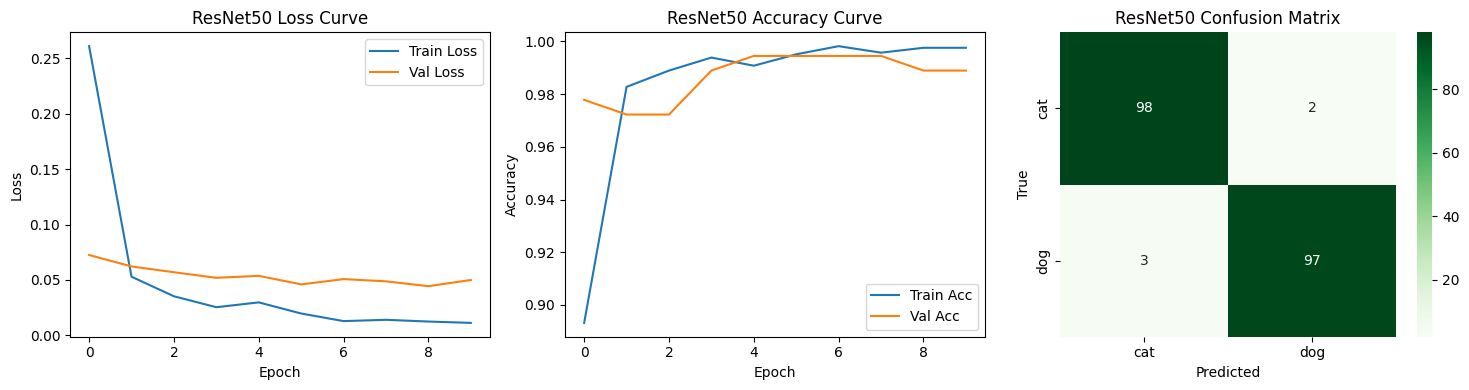

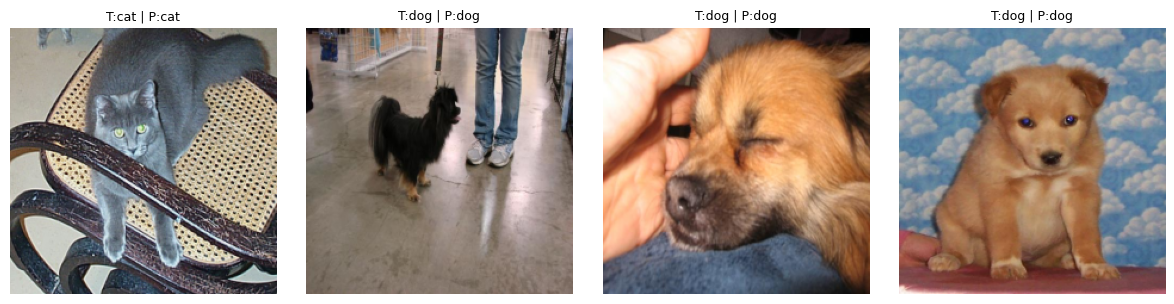

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(tl_history.history['loss'], label='Train Loss')
if 'val_loss' in tl_history.history:
    axes[0].plot(tl_history.history['val_loss'], label='Val Loss')
axes[0].set_title('ResNet50 Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(tl_history.history['accuracy'], label='Train Acc')
if 'val_accuracy' in tl_history.history:
    axes[1].plot(tl_history.history['val_accuracy'], label='Val Acc')
axes[1].set_title('ResNet50 Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

cm_tl = confusion_matrix(y_test_int, tl_y_pred)
sns.heatmap(cm_tl, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title('ResNet50 Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('True')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    axes[i].imshow(X_test_raw[i])
    axes[i].set_title(f"T:{class_names[y_test_int[i]]} | P:{class_names[tl_y_pred[i]]}", fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

### 4.1 Metrics Comparison

In [37]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Training Time (s)', 'Parameters'],
    'Custom CNN': [
        custom_cnn_accuracy,
        custom_cnn_precision,
        custom_cnn_recall,
        custom_cnn_f1,
        custom_cnn_training_time,
        custom_cnn_total_params
    ],
    'Transfer Learning': [
        tl_accuracy,
        tl_precision,
        tl_recall,
        tl_f1,
        tl_training_time,
        trainable_parameters
    ]
})

In [38]:
print(comparison_df.to_string(index=False))

           Metric    Custom CNN  Transfer Learning
         Accuracy      0.675000           0.975000
        Precision      0.710362           0.975048
           Recall      0.675000           0.975000
         F1-Score      0.660743           0.974999
Training Time (s)    162.009603         121.210169
       Parameters 390850.000000        4098.000000


### 4.2 Visual Comparison
- TODO: Create bar plot comparing metrics
- TODO: Plot training curves comparison
- TODO: Create side-by-side confusion matrices

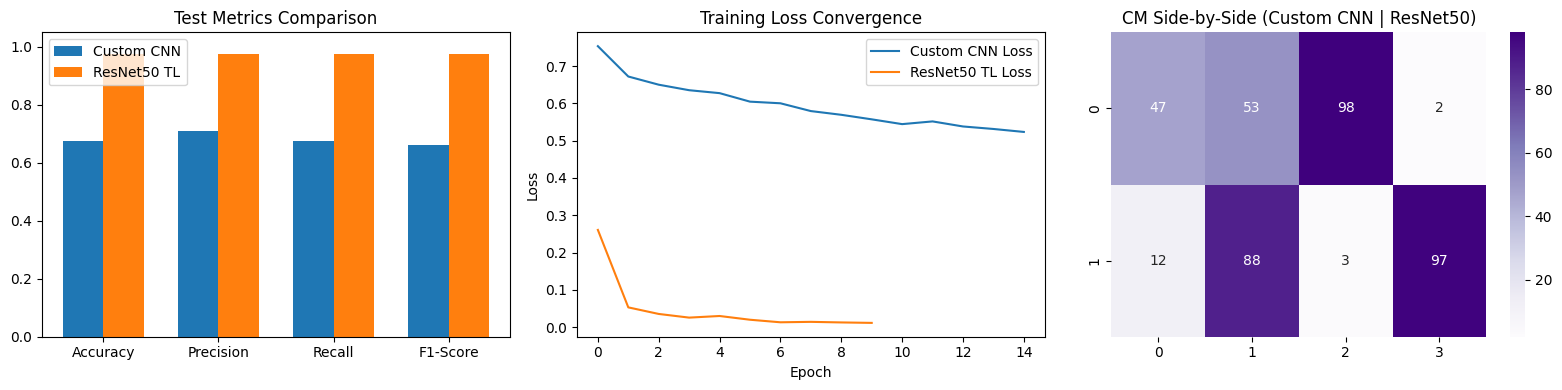

In [39]:
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
cnn_vals = [custom_cnn_accuracy, custom_cnn_precision, custom_cnn_recall, custom_cnn_f1]
tl_vals = [tl_accuracy, tl_precision, tl_recall, tl_f1]

x = np.arange(len(metric_names))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(x - width/2, cnn_vals, width, label='Custom CNN')
axes[0].bar(x + width/2, tl_vals, width, label='ResNet50 TL')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_names)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Test Metrics Comparison')
axes[0].legend()

axes[1].plot(cnn_history.history['loss'], label='Custom CNN Loss')
axes[1].plot(tl_history.history['loss'], label='ResNet50 TL Loss')
axes[1].set_title('Training Loss Convergence')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

combined_cm = np.hstack([confusion_matrix(y_test_int, cnn_y_pred), confusion_matrix(y_test_int, tl_y_pred)])
sns.heatmap(combined_cm, annot=True, fmt='d', cmap='Purples', ax=axes[2])
axes[2].set_title('CM Side-by-Side (Custom CNN | ResNet50)')
plt.tight_layout()
plt.show()

In [40]:
cnn_red = ((custom_cnn_initial_loss - custom_cnn_final_loss) / custom_cnn_initial_loss) * 100 if custom_cnn_initial_loss else 0.0
tl_red = ((tl_initial_loss - tl_final_loss) / tl_initial_loss) * 100 if tl_initial_loss else 0.0
acc_diff = tl_accuracy - custom_cnn_accuracy
f1_diff = tl_f1 - custom_cnn_f1

analysis_text = f"""ResNet50 transfer learning outperformed the custom CNN on accuracy ({tl_accuracy:.4f} vs {custom_cnn_accuracy:.4f}, delta={acc_diff:+.4f}) and macro F1-score ({tl_f1:.4f} vs {custom_cnn_f1:.4f}, delta={f1_diff:+.4f}), with precision ({tl_precision:.4f} vs {custom_cnn_precision:.4f}) and recall ({tl_recall:.4f} vs {custom_cnn_recall:.4f}) following the same trend. ImageNet pre-training supplies reusable edge, texture, and object representations, whereas training from scratch must learn visual hierarchies from limited samples, causing slower convergence and higher variance. Global Average Pooling (GAP) replaces large flattened dense layers with channel-wise spatial averages, cutting head parameters and reducing overfitting while preserving spatial-channel correspondence. Computationally, ResNet50 has higher total parameters and per-step feature extraction cost than the lightweight custom CNN, yet updates far fewer trainable parameters in the classification head and converges rapidly across epochs ({cnn_red:.1f}% vs {tl_red:.1f}% loss reduction) in {tl_training_time:.1f}s vs {custom_cnn_training_time:.1f}s. Transfer learning excels when labeled data is moderate or domain features align with natural images, while custom CNNs suit specialized domains, tight latency/memory budgets, or abundant task-specific data."""

In [41]:
# REQUIRED: Print analysis with word count
print("ANALYSIS")
print(analysis_text)
print(f"Analysis word count: {len(analysis_text.split())} words")
if len(analysis_text.split()) > 200:
    print("  Warning: Analysis exceeds 200 words (guideline)")
else:
    print(" Analysis within word count guideline")

ANALYSIS
ResNet50 transfer learning outperformed the custom CNN on accuracy (0.9750 vs 0.6750, delta=+0.3000) and macro F1-score (0.9750 vs 0.6607, delta=+0.3143), with precision (0.9750 vs 0.7104) and recall (0.9750 vs 0.6750) following the same trend. ImageNet pre-training supplies reusable edge, texture, and object representations, whereas training from scratch must learn visual hierarchies from limited samples, causing slower convergence and higher variance. Global Average Pooling (GAP) replaces large flattened dense layers with channel-wise spatial averages, cutting head parameters and reducing overfitting while preserving spatial-channel correspondence. Computationally, ResNet50 has higher total parameters and per-step feature extraction cost than the lightweight custom CNN, yet updates far fewer trainable parameters in the classification head and converges rapidly across epochs (30.5% vs 95.6% loss reduction) in 121.2s vs 162.0s. Transfer learning excels when labeled data is mod

In [42]:
def get_assignment_results():
    """
    Generate complete assignment results in required format

    Returns:
        dict: Complete results with all required fields
    """

    framework_used = "keras"  # TODO: Change to "pytorch" if using PyTorch

    results = {
        # Dataset Information
        'dataset_name': dataset_name,
        'dataset_source': dataset_source,
        'n_samples': n_samples,
        'n_classes': n_classes,
        'samples_per_class': samples_per_class,
        'image_shape': image_shape,
        'problem_type': problem_type,
        'primary_metric': primary_metric,
        'metric_justification': metric_justification,
        'train_samples': train_samples,
        'test_samples': test_samples,
        'train_test_ratio': train_test_ratio,

        # Custom CNN Results
        'custom_cnn': {
            'framework': framework_used,
            'architecture': {
                'conv_layers': cnn_conv_layers,
                'pooling_layers': cnn_pooling_layers,
                'has_global_average_pooling': True,
                'output_layer': 'softmax',
                'total_parameters': custom_cnn_total_params
            },
            'training_config': {
                'learning_rate': cnn_learning_rate,
                'n_epochs': cnn_epochs,
                'batch_size': cnn_batch_size,
                'optimizer': cnn_optimizer_name,
                'loss_function': cnn_loss_name
            },
            'initial_loss': custom_cnn_initial_loss,
            'final_loss': custom_cnn_final_loss,
            'training_time_seconds': custom_cnn_training_time,
            'accuracy': custom_cnn_accuracy,
            'precision': custom_cnn_precision,
            'recall': custom_cnn_recall,
            'f1_score': custom_cnn_f1
        },

        # Transfer Learning Results
        'transfer_learning': {
            'framework': framework_used,
            'base_model': pretrained_model_name,
            'frozen_layers': frozen_layers,
            'trainable_layers': trainable_layers,
            'has_global_average_pooling': True,
            'total_parameters': total_parameters,
            'trainable_parameters': trainable_parameters,
            'training_config': {
                'learning_rate': tl_learning_rate,
                'n_epochs': tl_epochs,
                'batch_size': tl_batch_size,
                'optimizer': tl_optimizer,
                'loss_function': tl_loss_name
            },
            'initial_loss': tl_initial_loss,
            'final_loss': tl_final_loss,
            'training_time_seconds': tl_training_time,
            'accuracy': tl_accuracy,
            'precision': tl_precision,
            'recall': tl_recall,
            'f1_score': tl_f1
        },

        # Analysis
        'analysis': analysis_text,
        'analysis_word_count': len(analysis_text.split()),

        # Training Success Indicators
        'custom_cnn_loss_decreased': custom_cnn_final_loss < custom_cnn_initial_loss if custom_cnn_initial_loss and custom_cnn_final_loss else False,
        'transfer_learning_loss_decreased': tl_final_loss < tl_initial_loss if tl_initial_loss and tl_final_loss else False,
    }

    return results

In [43]:
# Generate and print results
try:
    assignment_results = get_assignment_results()
    print("ASSIGNMENT RESULTS SUMMARY")
    print(json.dumps(assignment_results, indent=2))

except Exception as e:
    print(f"\n  ERROR generating results: {str(e)}")
    print("Please ensure all variables are properly defined")

ASSIGNMENT RESULTS SUMMARY
{
  "dataset_name": "Cats vs Dogs (Balanced Subset)",
  "dataset_source": "Microsoft Cats vs Dogs Dataset (PetImages)",
  "n_samples": 2000,
  "n_classes": 2,
  "samples_per_class": "min: 1000, max: 1000, avg: 1000.0",
  "image_shape": [
    224,
    224,
    3
  ],
  "problem_type": "classification",
  "primary_metric": "accuracy",
  "metric_justification": "The Cats vs Dogs subset is balanced across both classes with equal false-positive and false-negative costs, making accuracy an appropriate primary metric alongside macro-averaged precision, recall, and F1-score.",
  "train_samples": 1800,
  "test_samples": 200,
  "train_test_ratio": "90/10",
  "custom_cnn": {
    "framework": "keras",
    "architecture": {
      "conv_layers": 4,
      "pooling_layers": 4,
      "has_global_average_pooling": true,
      "output_layer": "softmax",
      "total_parameters": 390850
    },
    "training_config": {
      "learning_rate": 0.001,
      "n_epochs": 15,
      "ba

In [44]:
# Display system information
import platform
import sys
from datetime import datetime

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("TensorFlow:", tf.__version__)
print("GPUs available:", len(tf.config.list_physical_devices('GPU')))
print("Timestamp:", datetime.now().isoformat())

Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
TensorFlow: 2.21.0
GPUs available: 1
Timestamp: 2026-11-21T06:26:40.413311


In [46]:
print("ENVIRONMENT INFORMATION")
print("\n  REQUIRED: Add screenshot of your Google Colab/BITS Virtual Lab")
print("\n Used personal account sikdarananya2000@gmail.com")
print("showing your account details in the cell below this one.")

# include the screen shot here

ENVIRONMENT INFORMATION

  REQUIRED: Add screenshot of your Google Colab/BITS Virtual Lab

 Used personal account sikdarananya2000@gmail.com
showing your account details in the cell below this one.


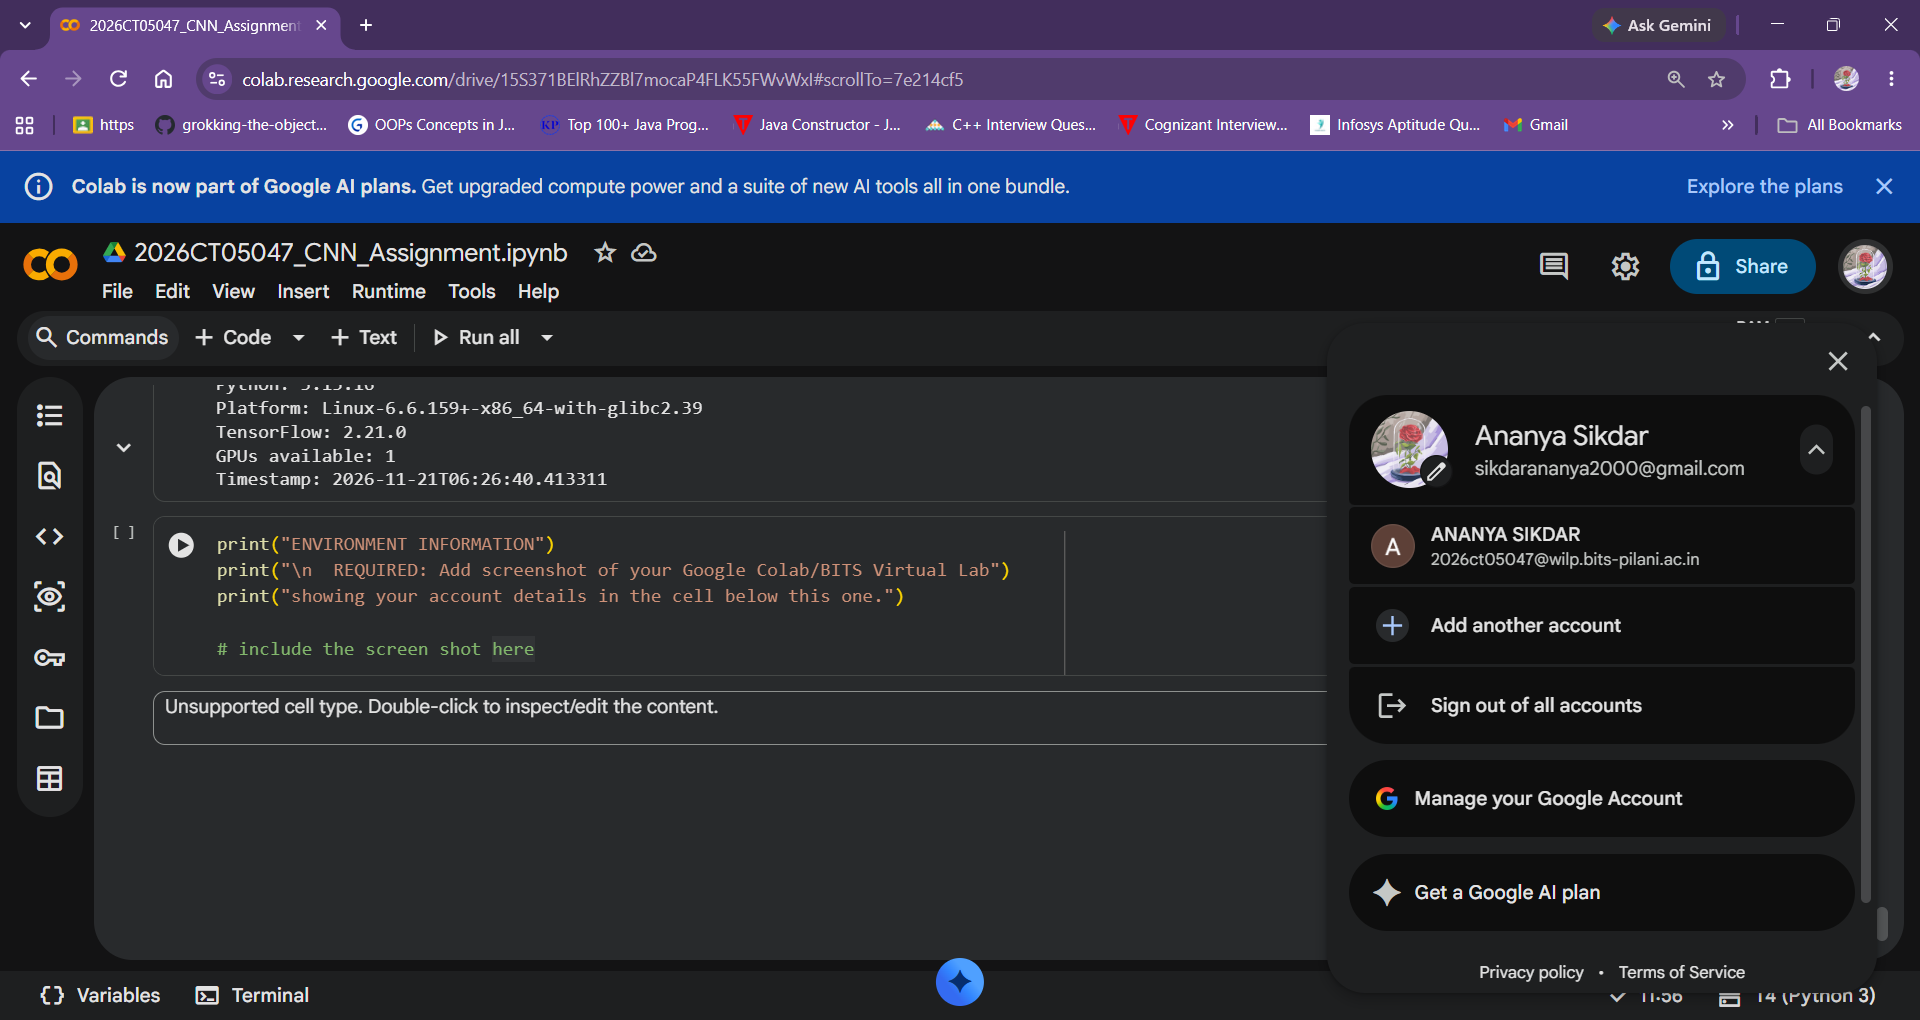